In [12]:
from langgraph.graph import StateGraph,START,END
from pydantic import BaseModel, Field
from dotenv import load_dotenv
from typing import TypedDict,Annotated,Any
from langchain_groq import ChatGroq
import os
import operator


In [2]:
load_dotenv()

True

In [3]:
model = ChatGroq(
    model="openai/gpt-oss-20b",
    api_key=os.environ.get("GROK_API_KEY")
)

In [4]:
class EvaluationSchema(BaseModel):
    feedback: str =Field(description="Detailed feedback for the essay")
    score:int=Field(description="alias_priority=Score out of 10,ge=0,le=10")
    

In [5]:
structured_output = model.with_structured_output(EvaluationSchema)

In [6]:
essay=""" Role of AI in India

Artificial Intelligence (AI) is becoming an important part of India's development. It is transforming industries, creating new opportunities, and helping solve many social and economic problems. India has a large pool of technology professionals and a growing startup ecosystem, which gives it strong potential to become a global leader in AI.
AI is playing an important role in **education** by providing personalized learning, intelligent tutoring systems, and tools that help students learn at their own pace. Teachers can also use AI to prepare learning materials and analyze student performance.
In **healthcare**, AI can help doctors detect diseases, analyze medical images, discover medicines, and provide better patient support. This can be especially useful for providing healthcare services in rural and remote areas.
AI is also helping **agriculture**. Farmers can use AI-based systems to predict weather, identify crop diseases, monitor soil conditions, and improve irrigation. These technologies can increase productivity and reduce losses.
In **business and industry**, AI is being used for automation, customer service, fraud detection, data analysis, cybersecurity, and decision-making. Indian companies are increasingly adopting AI to improve efficiency and compete in the global market.
AI also has an important role in **government services**. It can help improve public services, traffic management, disaster prediction, and the delivery of government schemes. India's growing digital infrastructure provides a strong foundation for these applications.
However, AI also brings challenges such as **job displacement, data privacy, cybersecurity, bias, and the need for new skills**. Therefore, India needs responsible AI development, strong regulations, quality education, and large-scale skill development.
AI can play a major role in making India more **developed, innovative, and globally competitive**. If India uses AI responsibly and ensures that its benefits reach all sections of society, AI can become a powerful tool for economic growth and social development.
"""

In [11]:
prompt="""Evaluate the language of the follwing essay and provide a feedback and assign a score out of 10\n {essay}"""
formatted_prompt = prompt.format(essay=essay)
result = structured_output.invoke(formatted_prompt)
print(result)

feedback='The essay presents a clear overview of AI’s impact across multiple sectors in India, using concise sentences and sector-specific examples. It is well-structured with consistent formatting (bolded headings) and maintains a formal, informative tone. However, the language is somewhat generic and could benefit from more varied sentence structures and richer vocabulary to enhance engagement. Minor grammatical issues such as missing articles (“the” before “AI”), inconsistent pluralization (“displacement” vs. “displacements”), and a lack of transition words between paragraphs slightly hinder flow. Overall, the essay demonstrates solid communicative competence but would score higher with more nuanced phrasing and tighter editing.' score=8


In [14]:
from typing import Annotated

class UPSCState(TypedDict):
    essay:str
    language_feedback:str
    analysis_feedback:str
    clarity_feedback:str
    overall_feedback:str
    individual_scores:Annotated[list[int], operator.add]
    avg_score:float

In [15]:
def evaluate_language(state:UPSCState):
    prompt='Evaluate the language of the follwing essay and provide a feedback and assign a score out of 10\n {state["essay"]}'
    formatted_prompt = prompt.format(essay=state["essay"])
    output = structured_output.invoke(formatted_prompt)
    state["language_feedback"] = output.feedback
    state["individual_scores"] = [output.score]

In [20]:
def evaluate_analysis(state:UPSCState):
    prompt='Evaluate the depth of anylysis of the follwing essay and provide a feedback and assign a score out of 10\n {state["essay"]}'
    formatted_prompt = prompt.format(essay=state["essay"])
    output = structured_output.invoke(formatted_prompt)
    state["anylysis_feedback"] = output.feedback
    state["individual_scores"] = [output.score]

In [17]:
def evaluate_thought(state:UPSCState):
    prompt='Evaluate the clerity of thought follwing essay and provide a feedback and assign a score out of 10\n {state["essay"]}'
    formatted_prompt = prompt.format(essay=state["essay"])
    output = structured_output.invoke(formatted_prompt)
    state["clarity_feedback"] = output.feedback
    state["individual_scores"] = [output.score]

In [18]:
def final_evaluation(state:UPSCState):
    prompt=f'based on the following feedbacks create a summarized feedback \n language feedback - {state['language_feedback']}\n depth of analysis feedback -{state["analysis_feedback"]}\n clarity of thought feedback - {state["analysis_feedback"]}'
    overall_feedback=model.invoke(prompt).content
    avg_score= sum(state['individual_scores'])/len(state['individual_scores'])
    return {'overall_feedback':overall_feedback,'avg_score':avg_score}

In [27]:
graph = StateGraph(UPSCState)
graph.add_node('evaluate_language', evaluate_language)
graph.add_node('evaluate_analysis', evaluate_analysis)
graph.add_node('evaluate_thought', evaluate_thought)
graph.add_node(' final_evaluation', final_evaluation)

graph.add_edge(START,'evaluate_language')
graph.add_edge(START,'evaluate_analysis')
graph.add_edge(START,'evaluate_thought')

graph.add_edge('evaluate_language','final_evaluation')
graph.add_edge('evaluate_analysis','final_evaluation')
graph.add_edge('evaluate_thought','final_evaluation')
graph.add_edge('final_evaluation',END)

graph.add_node("final_evaluation", final_evaluation)

workflow = graph.compile()

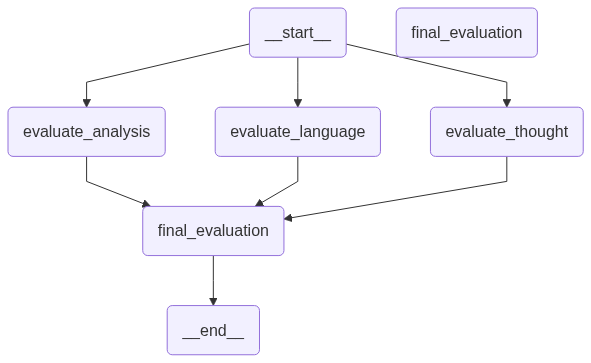

In [25]:
workflow

In [31]:
initial_state = {
    'essay': essay
}

In [ ]:
workflow.invoke(initial_state)

KeyError: 'state'